# A minimal and educational BS–IVF baseline

This notebook implements the following pipeline:

> **Clean IvyDB quotes → use or recover Black–Scholes implied volatility → smooth IV across moneyness and maturity → use the fitted IV in Black–Scholes → calculate price and delta → test next-day pricing and hedging.**

The aim is not to build a production-grade data system. It is to make the **financial logic and modelling steps visible**.

There are no classes, abstract interfaces, automatic file discovery, or large configuration systems. Each major block corresponds to one conceptual step.

## Model used

On each date $t$, we fit the simple implied-volatility function (Model 3)

$$
\widehat{\sigma}_t(m,T)
=
\beta_{0,t}
+\beta_{1,t}m
+\beta_{2,t}m^2
+\beta_{3,t}T
+\beta_{4, t}T^2
+\beta_{4,t}mT,
$$

where

$$
m=\log\left(\frac{K}{F}\right)
$$
is the log-moneyness

This is a **Dumas-style ad hoc implied-volatility function**: a low-order polynomial that smooths Black–Scholes implied volatility across moneyness and maturity.

It is not the deterministic-volatility PDE model by Dupire.

## What this notebook deliberately leaves out <span style='color:red'> **!!!** </span>

- transaction costs;
- a tradable SPX hedge proxy such as ES futures or SPY;
- sophisticated quote weighting;
- LV and Heston calibration;
- extensive robustness checks;
- a full replication of every detail in Dumas, Fleming and Whaley.

Those can be added only after this baseline is understood and working.

## 1. Imports and file names

Place the notebook in the same folder as the four CSV files below.

Change only the filenames in this cell when your local names differ.

In [341]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import brentq
from scipy.stats import norm

pd.set_option("display.max_columns", 50)

DATA_FOLDER = Path(".")

OPTIONS_FILE = DATA_FOLDER / "one_month_spx_option_price.csv"
SPOT_FILE = DATA_FOLDER / "one_month_spx_security_price.csv"
FORWARD_FILE = DATA_FOLDER / "one_month_spx_forward_price.csv"
RATE_FILE = DATA_FOLDER / "one_month_spx_zero_coupon_yield_curve.csv"

TARGET_SECID = 108105

print("Imports completed.")

Imports completed.


## 2. Load the raw CSV files

Each table has one specific role:

- `options`: listed SPX option quotes;
- `spot`: daily SPX index level;
- `forwards`: forward index level for each option expiry and settlement type;
- `rates`: zero-coupon interest-rate curve for each date.

We keep only the columns needed for this baseline.

In [342]:
options = pd.read_csv(OPTIONS_FILE, low_memory=False)
spot = pd.read_csv(SPOT_FILE)
forwards = pd.read_csv(FORWARD_FILE)
rates = pd.read_csv(RATE_FILE)

print("Raw shapes")
print("options: ", options.shape)
print("spot:    ", spot.shape)
print("forwards:", forwards.shape)
print("rates:   ", rates.shape)

Raw shapes
options:  (326964, 27)
spot:     (20, 7)
forwards: (1192, 7)
rates:    (220, 3)


## 3. Basic cleaning

This is intentionally limited to the checks that materially affect the experiment.

We:

1. parse dates;
2. convert `strike_price`, which IvyDB stores multiplied by 1,000;
3. construct the bid–ask midpoint;
4. retain standard European SPX contracts;
5. remove invalid or extremely wide quotes;
6. keep options with 14–365 calendar days to expiry.

We do **not** fill missing option prices, strikes, dates, or forwards.

In [343]:
# The Option Prices download contains a forward_price column, but in this
# sample it is entirely missing. We use the separate Forward Price table.
if "forward_price" in options.columns:
    options = options.drop(columns=["forward_price"])

# Parse dates.
options["date"] = pd.to_datetime(options["date"])
options["exdate"] = pd.to_datetime(options["exdate"])

spot["date"] = pd.to_datetime(spot["date"])

forwards["date"] = pd.to_datetime(forwards["date"])
forwards["expiration"] = pd.to_datetime(forwards["expiration"])

rates["date"] = pd.to_datetime(rates["date"])

# Rename the forward-table columns to match the option-table names.
forwards = forwards.rename(
    columns={
        "expiration": "exdate",
        "AMSettlement": "am_settlement",
        "ForwardPrice": "forward_price",
    }
)

# Convert important columns to numbers.
numeric_columns = [
    "secid",
    "strike_price",
    "best_bid",
    "best_offer",
    "impl_volatility",
    "optionid",
    "am_settlement",
    "contract_size",
]

for column in numeric_columns:
    options[column] = pd.to_numeric(options[column], errors="coerce")

# IvyDB stores strike_price as strike × 1,000.
options["strike"] = options["strike_price"] / 1000

# A simple estimate of the market price.
options["mid"] = (options["best_bid"] + options["best_offer"]) / 2
options["spread"] = options["best_offer"] - options["best_bid"]
options["relative_spread"] = options["spread"] / options["mid"]

# Time remaining until expiry.
options["dte"] = (options["exdate"] - options["date"]).dt.days
options["T"] = options["dte"] / 365

rows_before = len(options)

standard_flag = options["ss_flag"].astype(str).isin(["0", "0.0"])

# the cleaned copy of option data
options = options[
    (options["secid"] == TARGET_SECID)
    & (options["exercise_style"].astype(str).str.upper() == "E")
    & standard_flag
    & (options["contract_size"] == 100)
    & (options["cp_flag"].isin(["C", "P"]))
    & (options["strike"] > 0)
    & (options["best_bid"] > 0)
    & (options["best_offer"] >= options["best_bid"])
    & (options["mid"] > 0)
    & (options["relative_spread"] <= 0.50)
    & (options["dte"].between(14, 365))
].copy()

print(f"Rows before basic cleaning: {rows_before:,}")
print(f"Rows after basic cleaning:  {len(options):,}")

Rows before basic cleaning: 326,964
Rows after basic cleaning:  316,297


In [344]:
average_spread = options["spread"].mean()
median_spread = options["spread"].median()
average_relative_spread = options["relative_spread"].mean()

print(f"Average bid–ask spread: {average_spread:.4f}")
print(f"Median bid–ask spread: {median_spread:.4f}")
print(f"Average relative spread: {average_relative_spread:.2%}")

Average bid–ask spread: 4.4544
Median bid–ask spread: 1.0000
Average relative spread: 2.86%


0.500     1.0
0.750     7.8
0.900    11.0
0.950    16.2
0.995    27.7
Name: spread, dtype: float64
Min spread: 0.04999999999999982
Max spread: 80.0


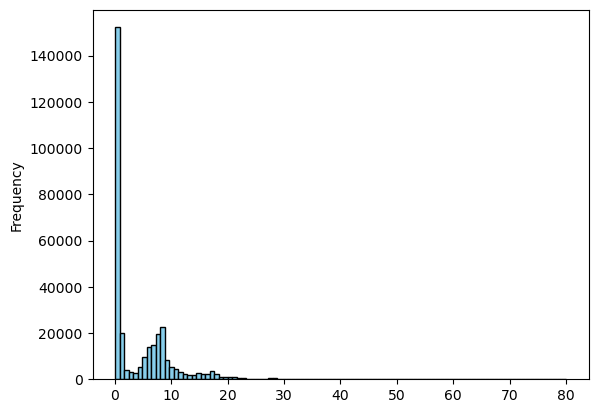

In [345]:
options["spread"].plot(kind="hist", bins=100, edgecolor="black", color="skyblue")
print(options["spread"].quantile([0.5, 0.75, 0.9, 0.95, 0.995]))

print("Min spread:", min(options["spread"]))
print("Max spread:", max(options["spread"]))

## 4. Attach spot and forward prices

The merge keys matter:

- spot is matched by `(secid, date)`;
- forward price is matched by `(secid, date, exdate, am_settlement)`.

The settlement flag is necessary because SPX can have different AM- and PM-settled contracts with the same calendar expiry.

In [346]:
# Keep only the needed support-data columns.
spot = spot[["secid", "date", "close"]].rename(columns={"close": "spot"})

forwards = forwards[
    ["secid", "date", "exdate", "am_settlement", "forward_price"]
]

# Match the same-day SPX level.
options = options.merge(
    spot,
    on=["secid", "date"],
    how="left",
)

# Match the forward for the exact expiry and settlement type.
options = options.merge(
    forwards,
    on=["secid", "date", "exdate", "am_settlement"],
    how="left",
)

print("Missing spot values:", options["spot"].isna().sum())
print("Missing forward values:", options["forward_price"].isna().sum())

Missing spot values: 0
Missing forward values: 0


## 5. Interpolate the interest rate

IvyDB gives the zero curve only at selected maturities such as 30, 60, or 91 days.

For an option with, say, 47 days remaining, we linearly interpolate between the surrounding curve points.

The downloaded rates appear in percentage points, so a value such as `5.30` is converted to `0.0530`.

For this first notebook, the rate is treated as continuously compounded:

$$
D(t,T)=e^{-r(T-t)}.
$$
(note, `T` in the code denotes $T-t$, i.e. time to maturity already)

<span style='color:red'> **!!!** </span>



In [347]:
rates["rate_decimal"] = rates["rate"] / 100

options["rate"] = np.nan

# Work one date at a time because each date has its own yield curve.
for date in options["date"].dropna().unique():
    option_rows = options["date"] == date
    curve_today = rates[rates["date"] == date].sort_values("days")

    if len(curve_today) == 0:
        continue

    options.loc[option_rows, "rate"] = np.interp(
        options.loc[option_rows, "dte"],
        curve_today["days"],
        curve_today["rate_decimal"],
    )

options["discount"] = np.exp(-options["rate"] * options["T"])

print("Missing interpolated rates:", options["rate"].isna().sum())

Missing interpolated rates: 0


## 6. Construct moneyness and select out-of-the-money options

We measure moneyness relative to the forward:

$$
m=
\log\left(\frac{K}{F}\right).
$$

- $m<0$: strike below the forward;
- $m=0$: approximately at the money;
- $m>0$: strike above the forward.

We fit the surface using out-of-the-money options:

- calls with $K\geq F$;
- puts with $K<F$.

Near-ATM options usually have the most stable implied volatilities. Deep ITM options can be problematic because price is dominated by intrinsic value, while deep OTM options can be problematic because price and vega are very small. A custom choice here is to select only OTM options whose log_moneyness in absolute value is below 0.3 <span style='color:red'> **!!!** </span>


In [348]:
# Remove rows that could not be matched to essential support data.
options = options.dropna(
    subset=["spot", "forward_price", "rate", "discount"]
).copy()

# old moneyness
options["moneyness"] = options["strike"] / options["forward_price"] - 1  

# new moneyness
options["log_moneyness"] = np.log(
    options["strike"] / options["forward_price"]
) 

call_is_otm = (
    (options["cp_flag"] == "C")
    & (options["strike"] >= options["forward_price"])
)

put_is_otm = (
    (options["cp_flag"] == "P")
    & (options["strike"] < options["forward_price"])
)

options["is_otm"] = call_is_otm | put_is_otm

# Avoid extreme wings in the first implementation.
options = options[
    options["is_otm"]
    & (options["log_moneyness"].abs() <= 0.30)
].copy()

print("Rows in the modelling sample:", len(options))
print("Dates:", options["date"].nunique())
print("Unique contracts:", options["optionid"].nunique())

Rows in the modelling sample: 125746
Dates: 20
Unique contracts: 10412


## 7. Black–Scholes price, delta, and implied volatility

We use Black–Scholes in **forward form**.

For a call,

$$
C=D\left(FN(d_1)-KN(d_2)\right),
$$

where

$$
d_1=
\frac{\log(F/K)+\frac12\sigma^2T}{\sigma\sqrt{T}},
\qquad
d_2=d_1-\sigma\sqrt{T}.
$$

The put formula is analogous (call-put parity).

### Delta

The ordinary Black–Scholes spot delta is

$$
\Delta_{\text{call}}
=
D\frac{F}{S}N(d_1),
$$

and

$$
\Delta_{\text{put}}
=
D\frac{F}{S}\left(N(d_1)-1\right).
$$

The factor $DF/S$ is the observed carry adjustment implied by the forward price.

### Missing implied volatility

Where IvyDB's `impl_volatility` is missing, we numerically solve for the volatility that makes the Black–Scholes price equal to the observed midpoint.

In [349]:
def bs_price(cp_flag, forward, strike, T, discount, sigma):
    sqrt_T = np.sqrt(T)

    d1 = (
        np.log(forward / strike)
        + 0.5 * sigma**2 * T
    ) / (sigma * sqrt_T)

    d2 = d1 - sigma * sqrt_T

    call_price = discount * (
        forward * norm.cdf(d1)
        - strike * norm.cdf(d2)
    )

    put_price = discount * (
        strike * norm.cdf(-d2)
        - forward * norm.cdf(-d1)
    )

    return np.where(cp_flag == "C", call_price, put_price)


def bs_delta(cp_flag, spot, forward, strike, T, discount, sigma):
    sqrt_T = np.sqrt(T)

    d1 = (
        np.log(forward / strike)
        + 0.5 * sigma**2 * T
    ) / (sigma * sqrt_T)

    carry = discount * forward / spot

    call_delta = carry * norm.cdf(d1)
    put_delta = carry * (norm.cdf(d1) - 1)

    return np.where(cp_flag == "C", call_delta, put_delta)


def implied_volatility(row):
    price = row["mid"]
    forward = row["forward_price"]
    strike = row["strike"]
    T = row["T"]
    discount = row["discount"]
    cp_flag = row["cp_flag"]

    # European no-arbitrage price bounds in forward form.
    if cp_flag == "C":
        lower_bound = discount * max(forward - strike, 0)
        upper_bound = discount * forward
    else:
        lower_bound = discount * max(strike - forward, 0)
        upper_bound = discount * strike

    if not (lower_bound < price < upper_bound):
        return np.nan

    def pricing_error(sigma):
        model_price = bs_price(
            cp_flag,
            forward,
            strike,
            T,
            discount,
            sigma,
        )
        return float(model_price - price)

    try:
        return brentq(pricing_error, 0.001, 5.0)
    except ValueError:
        return np.nan

## 8. Use IvyDB IV and recover only the missing values

The simplest approach is:

1. retain a valid IvyDB IV where it exists;
2. invert the midpoint only where the supplied IV is missing or invalid.

This avoids recomputing tens of thousands of already available implied volatilities.

In [350]:
options["market_iv"] = pd.to_numeric(
    options["impl_volatility"],
    errors="coerce",
)

valid_vendor_iv = options["market_iv"].between(0.001, 5.0)
missing_iv = ~valid_vendor_iv

print(f"IVs to recover: {missing_iv.sum():,}")

recovered_iv = options.loc[missing_iv].apply(
    implied_volatility,
    axis=1,
)

options.loc[missing_iv, "market_iv"] = recovered_iv

rows_before_iv_filter = len(options)

options = options[
    options["market_iv"].between(0.001, 5.0)
].copy()

print(f"Rows before IV recovery/filter: {rows_before_iv_filter:,}")
print(f"Rows after IV recovery/filter:  {len(options):,}")

IVs to recover: 0
Rows before IV recovery/filter: 125,746
Rows after IV recovery/filter:  125,746


In [351]:
options["price_from_market_iv"] = bs_price(
    options["cp_flag"].to_numpy(),
    options["forward_price"].to_numpy(),
    options["strike"].to_numpy(),
    options["T"].to_numpy(),
    options["discount"].to_numpy(),
    options["market_iv"].to_numpy(),
)

options["market_iv_repricing_error"] = (
    options["price_from_market_iv"] - options["mid"]
)

print(
    "Market-IV repricing MAE:",
    options["market_iv_repricing_error"].abs().mean()
)

Market-IV repricing MAE: 0.1228611151786524


0.500    0.4
0.750    0.6
0.900    0.9
0.950    1.1
0.995    3.5
Name: spread, dtype: float64
Min spread: 0.04999999999999982
Max spread: 12.900000000000006


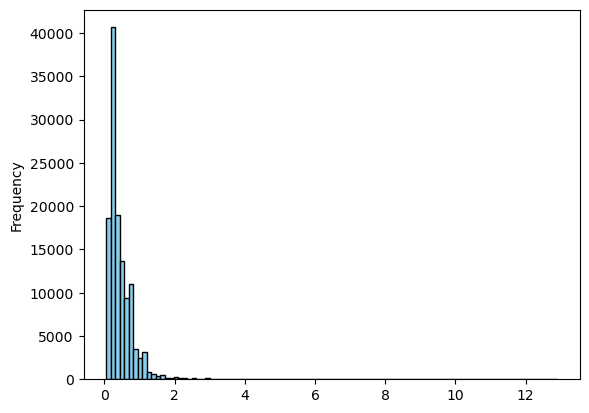

In [352]:
# post-cleaning options

options["spread"].plot(kind="hist", bins=100, edgecolor="black", color="skyblue")
print(options["spread"].quantile([0.5, 0.75, 0.9, 0.95, 0.995]))

print("Min spread:", min(options["spread"]))
print("Max spread:", max(options["spread"]))

## 9. Fit the daily implied-volatility function (CHANGED. DESCRIPTION BELOW NO LONGER APPLIES)

For every trading date, we regress market IV on

$$
1,\quad m,\quad m^2,\quad T,\quad T^2, \quad mT.
$$

This is ordinary least squares.

The fitted coefficients are allowed to change every day. That is the daily recalibration step.

The code below is deliberately explicit:

- `X` is the matrix of explanatory variables;
- `y` is the vector of observed implied volatilities;
- `np.linalg.lstsq` finds the coefficient vector $\beta$ that minimises squared fitting error.

In [353]:
from scipy.optimize import least_squares

def make_design_matrix(k, T):  # we are fitting one smile per maturity now, not one big poly for all, so this is useless
    return np.column_stack(
        [
            np.ones(len(k)),
            k,
            k**2,
            T,
            T**2,
            k * T,
        ]
    )


coefficient_rows = []

for (date, exdate), expiry_options in options.groupby(
    ["date", "exdate"]
):
    if len(expiry_options) < 10:
        continue

    k = expiry_options["log_moneyness"].to_numpy()

    X = np.column_stack(
        [
            np.ones(len(k)),
            k,
            k**2,
        ]
    )

    y = expiry_options["market_iv"].to_numpy()
    vega = np.abs(expiry_options["vega"].to_numpy())

    beta = np.linalg.lstsq(
        X * vega[:, None],
        y * vega,
        rcond=None,
    )[0]

    coefficient_rows.append(
        {
            "date": date,
            "exdate": exdate,
            "beta_0": beta[0],
            "beta_k": beta[1],
            "beta_k2": beta[2],
        }
    )

coefficients = pd.DataFrame(coefficient_rows)

print("Dates successfully fitted:", len(coefficients))
coefficients.head()

Dates successfully fitted: 718


,date,exdate,beta_0,beta_k,beta_k2
0,2024-03-01,2024-03-18,0.100774,-0.558257,6.284114
1,2024-03-01,2024-03-19,0.102521,-0.536486,5.995872
2,2024-03-01,2024-03-20,0.108811,-0.521958,5.475957
3,2024-03-01,2024-03-21,0.110131,-0.454459,5.540569
4,2024-03-01,2024-03-22,0.111134,-0.455976,5.370849


## 10. Calculate fitted IV, same-day price, and delta

We merge each date's coefficients back onto its option rows.

The fitted IV is then passed into the ordinary Black–Scholes formulas.

A small positive floor is applied because an unconstrained polynomial can occasionally predict a negative volatility in the wings.

In [354]:
options = options.merge(
    coefficients,
    on=["date", "exdate"],
    how="inner",
)

options["fitted_iv"] = (
    options["beta_0"]
    + options["beta_k"] * options["log_moneyness"]
    + options["beta_k2"] * options["log_moneyness"]**2
)

options["fitted_iv"] = options["fitted_iv"].clip(0.01, 3.0)

options["model_price"] = bs_price(
    options["cp_flag"].to_numpy(),
    options["forward_price"].to_numpy(),
    options["strike"].to_numpy(),
    options["T"].to_numpy(),
    options["discount"].to_numpy(),
    options["fitted_iv"].to_numpy(),
)

options["model_delta"] = bs_delta(
    options["cp_flag"].to_numpy(),
    options["spot"].to_numpy(),
    options["forward_price"].to_numpy(),
    options["strike"].to_numpy(),
    options["T"].to_numpy(),
    options["discount"].to_numpy(),
    options["fitted_iv"].to_numpy(),
)

options["same_day_price_error"] = (
    options["model_price"] - options["mid"]
)

same_day_rmse = np.sqrt(
    np.mean(options["same_day_price_error"]**2)
)

same_day_mae = np.mean(
    np.abs(options["same_day_price_error"])
)

print(f"Same-day price RMSE: {same_day_rmse:.4f}")
print(f"Same-day price MAE:  {same_day_mae:.4f}")

Same-day price RMSE: 2.0080
Same-day price MAE:  1.4713


In [355]:
# polynomial (IVF) fitting MAE for the vol 
iv_mae = np.mean(
    np.abs(options["fitted_iv"] - options["market_iv"])
)
print("IV fitting MAE:", iv_mae)

IV fitting MAE: 0.0071836713950807225


## 11. Plot one fitted daily surface

A useful visual check is whether the fitted curve follows the broad smile/skew without chasing every noisy quote.

Each line below corresponds to one expiry on the chosen date.

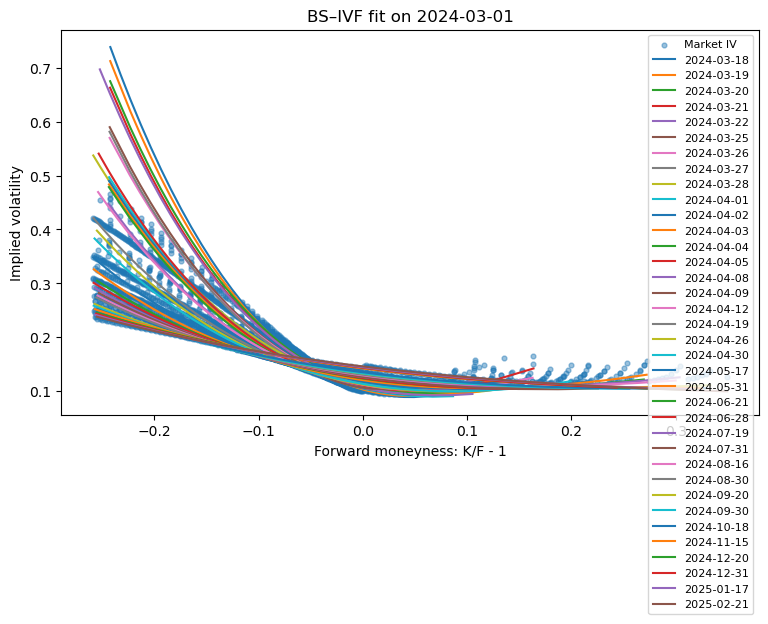

In [356]:
example_date = options["date"].min()

example = options[
    options["date"] == example_date
].copy()

plt.figure(figsize=(9, 5))

plt.scatter(
    example["moneyness"],
    example["market_iv"],
    s=12,
    alpha=0.45,
    label="Market IV",
)

for exdate, expiry_options in example.groupby("exdate"):
    expiry_options = expiry_options.sort_values("moneyness")

    plt.plot(
        expiry_options["moneyness"],
        expiry_options["fitted_iv"],
        linewidth=1.5,
        label=str(exdate.date()),
    )

plt.title(f"BS–IVF fit on {example_date.date()}")
plt.xlabel("Forward moneyness: K/F - 1")
plt.ylabel("Implied volatility")
plt.legend(fontsize=8)
plt.show()

## 12. Match each option to the next trading day

The out-of-sample experiment must compare the **same contract** on consecutive trading dates.

We therefore:

1. build the next-trading-day calendar from the SPX spot file;
2. attach the expected next date to every observation;
3. merge on `(optionid, expected next date)`.

This prevents an option that disappears for several days from being mistaken for a one-day observation.

In [357]:
trading_dates = sorted(spot["date"].unique())

next_date_map = {
    trading_dates[i]: trading_dates[i + 1]
    for i in range(len(trading_dates) - 1)
}

today = options.copy()
today["next_date"] = today["date"].map(next_date_map)

tomorrow_columns = [
    "optionid",
    "date",
    "mid",
    "best_bid",
    "best_offer",
    "spot",
    "forward_price",
    "strike",
    "T",
    "discount",
    "moneyness",
    "cp_flag",
    "log_moneyness"
]

tomorrow = options[tomorrow_columns].copy()

tomorrow = tomorrow.rename(
    columns={
        "date": "date_next",
        "mid": "mid_next",
        "best_bid": "best_bid_next",
        "best_offer": "best_offer_next",
        "spot": "spot_next",
        "forward_price": "forward_price_next",
        "strike": "strike_next",
        "T": "T_next",
        "discount": "discount_next",
        "moneyness": "moneyness_next",
        "cp_flag": "cp_flag_next",
        "log_moneyness": "log_moneyness_next"
    }
)

pairs = today.merge(
    tomorrow,
    left_on=["optionid", "next_date"],
    right_on=["optionid", "date_next"],
    how="inner",
)

print("One-day option pairs:", len(pairs))
print("Current dates represented:", pairs["date"].nunique())

One-day option pairs: 113216
Current dates represented: 19


## 13. One-day-ahead pricing

This is the crucial out-of-sample step.

For an option observed on dates $t$ and $t+1$:

- keep the coefficients $\beta_t$ fitted on date $t$;
- update moneyness and time to maturity using date-$t+1$ market inputs;
- compute tomorrow's predicted IV;
- use Black–Scholes to predict tomorrow's option price.

The coefficients are **not recalibrated using tomorrow's quotes** before making the prediction.

In [358]:
pairs["predicted_iv_next"] = (
    pairs["beta_0"]
    + pairs["beta_k"] * pairs["log_moneyness_next"]
    + pairs["beta_k2"] * pairs["log_moneyness_next"]**2
)

pairs["predicted_iv_next"] = pairs["predicted_iv_next"].clip(
    0.01,
    3.0,
)

pairs["predicted_price_next"] = bs_price(
    pairs["cp_flag_next"].to_numpy(),
    pairs["forward_price_next"].to_numpy(),
    pairs["strike_next"].to_numpy(),
    pairs["T_next"].to_numpy(),
    pairs["discount_next"].to_numpy(),
    pairs["predicted_iv_next"].to_numpy(),
)

pairs["next_day_price_error"] = (
    pairs["predicted_price_next"] - pairs["mid_next"]
)

next_day_price_rmse = np.sqrt(
    np.mean(pairs["next_day_price_error"]**2)
)

next_day_price_mae = np.mean(
    np.abs(pairs["next_day_price_error"])
)

print(f"Next-day price RMSE: {next_day_price_rmse:.4f}")
print(f"Next-day price MAE:  {next_day_price_mae:.4f}")

Next-day price RMSE: 2.5311
Next-day price MAE:  1.8982


## 14. One-day delta-hedging error

For a **long option**, the option value changes by

$$
C_{t+1}-C_t.
$$

A delta hedge holds $\Delta_t$ units of the underlying, which changes in value by

$$
\Delta_t(S_{t+1}-S_t).
$$

The residual hedging error is

$$
\varepsilon^{\text{hedge}}_{t+1}
=
(C_{t+1}-C_t)
-
\Delta_t(S_{t+1}-S_t).
$$

A perfect one-day hedge would give zero.

This first version ignores one-day cash-account interest and transaction costs. Those are small refinements compared with understanding the core hedge construction.

SPX itself is not directly tradable, so this is a **theoretical index-unit hedge** used to compare model deltas. A practical hedge with ES futures or SPY requires a separate conversion.

In [359]:
pairs["option_change"] = (
    pairs["mid_next"] - pairs["mid"]
)

pairs["hedge_change"] = (
    pairs["model_delta"]
    * (pairs["spot_next"] - pairs["spot"])
)

pairs["hedging_error"] = (
    pairs["option_change"] - pairs["hedge_change"]
)

hedging_rmse = np.sqrt(
    np.mean(pairs["hedging_error"]**2)
)

hedging_mae = np.mean(
    np.abs(pairs["hedging_error"])
)

hedging_bias = np.mean(
    pairs["hedging_error"]
)

print(f"Hedging-error RMSE: {hedging_rmse:.4f}")
print(f"Hedging-error MAE:  {hedging_mae:.4f}")
print(f"Hedging-error bias: {hedging_bias:.4f}")

Hedging-error RMSE: 1.3044
Hedging-error MAE:  0.8976
Hedging-error bias: -0.0492


In [360]:
unhedged_mae = pairs["option_change"].abs().mean()
hedged_mae = pairs["hedging_error"].abs().mean()

print("Unhedged MAE:", unhedged_mae)
print("Hedged MAE:", hedged_mae)
print("Improvement:", 1 - hedged_mae / unhedged_mae)

Unhedged MAE: 4.249427201102318
Hedged MAE: 0.8976285126363213
Improvement: 0.788764821667383


In [361]:
# Same-day: is the model price inside this option's own bid-ask interval?
options["inside_bid_ask"] = options["model_price"].between(
    options["best_bid"],
    options["best_offer"],
)

# Distance outside the quoted interval; zero when inside.
options["outside_spread_error"] = np.maximum(
    options["best_bid"] - options["model_price"],
    options["model_price"] - options["best_offer"],
)
options["outside_spread_error"] = options[
    "outside_spread_error"
].clip(lower=0)

# Midpoint error measured in units of that option's half-spread.
options["normalised_error"] = (
    options["same_day_price_error"].abs()
    / (options["spread"] / 2)
)

print("Inside bid-ask:", options["inside_bid_ask"].mean())
print(
    "Outside-spread MAE:",
    options["outside_spread_error"].mean(),
)
print(
    "Median error / half-spread:",
    options["normalised_error"].median(),
)

Inside bid-ask: 0.08020135829370317
Outside-spread MAE: 1.2519497684572638
Median error / half-spread: 6.1180156704328565


## 15. Save the small set of outputs

Only three files are saved:

- daily IVF coefficients;
- one-day contract-level results;
- a compact summary.

These are enough to compare BS–IVF later with local volatility, Heston, and neural SDE.

In [362]:
output_folder = Path("bs_ivf_outputs")
output_folder.mkdir(exist_ok=True)

summary = pd.DataFrame(
    {
        "metric": [
            "same_day_price_rmse",
            "same_day_price_mae",
            "next_day_price_rmse",
            "next_day_price_mae",
            "hedging_rmse",
            "hedging_mae",
            "hedging_bias",
            "number_of_clean_option_rows",
            "number_of_one_day_pairs",
        ],
        "value": [
            same_day_rmse,
            same_day_mae,
            next_day_price_rmse,
            next_day_price_mae,
            hedging_rmse,
            hedging_mae,
            hedging_bias,
            len(options),
            len(pairs),
        ],
    }
)

coefficients.to_csv(
    output_folder / "daily_ivf_coefficients.csv",
    index=False,
)

pairs.to_csv(
    output_folder / "one_day_results.csv",
    index=False,
)

summary.to_csv(
    output_folder / "summary.csv",
    index=False,
)

summary

,metric,value
0,same_day_price_rmse,2.007951
1,same_day_price_mae,1.471263
2,next_day_price_rmse,2.531067
3,next_day_price_mae,1.898212
4,hedging_rmse,1.304421
5,hedging_mae,0.897629
6,hedging_bias,-0.049198
7,number_of_clean_option_rows,125746.000000
8,number_of_one_day_pairs,113216.000000


# What to understand before moving on

The complete model is now only:

1. **Market IV:** the volatility that reproduces each market quote in Black–Scholes.
2. **IVF fit:** a daily polynomial smooth of those IV observations.
3. **Price:** Black–Scholes evaluated using fitted IV.
4. **Delta:** ordinary Black–Scholes delta evaluated using fitted IV.
5. **Out-of-sample test:** freeze today's fitted coefficients and evaluate tomorrow.
6. **Hedge test:** compare the option's actual one-day change with the gain from today's delta hedge.

Most of the remaining work in the UROP should reuse the same cleaned option pairs and evaluation definitions. Local volatility, Heston, and neural SDE should change the **model-specific price and hedge calculation**, not rebuild the entire data pipeline.

## References

- Dumas, Fleming and Whaley (1998), *Implied Volatility Functions: Empirical Tests*.
- Gierjatowicz, Sabate-Vidales, Šiška, Szpruch and Žurič (2020), *Robust Pricing and Hedging via Neural SDEs*.